# Financial Transaction Fraud Detector
## Notebook 05 - Deployment & Web Application

**Owner:** Ali Mahmoud  
**Role:** Deployment & Web Application  
**Course / University:** AI in Cybersecurity, Sohag University  
**Date:** 2026-11-24

**Goal.** Show how the Streamlit app is built, run its six example transactions and the batch check, and explain how it is deployed to Streamlit Community Cloud.

**Inputs:** `models/model.joblib`, `models/model_meta.json`, `data/sample.csv`, `app.py`

**Outputs:** `reports/app_presets.json`, `reports/screens/*.png`

Run the notebooks in order 01, 02, 03, 04a, 04b, 05; each one reads the files saved by the previous one.

## 1. How the app is built

The web app is a single Streamlit file, `app.py`, that reuses the shared code in `src/`. It reads **only files
inside the repository** and makes **no network calls**, so it works the same on a laptop and in the cloud.

```
app.py                     the web app (4 tabs)
src/features.py            builds features exactly as in training
src/scoring.py             loads the model, turns scores into Approve / Review / Block and risk points
src/explain.py             plain-English warning signs
src/batch.py               checks uploaded CSV files (empty, missing columns, wrong values, too many rows)
src/presets.py             the six example transactions (synthetic)
models/model.joblib        the trained primary model (from notebook 04a)
models/model_meta.json     features, thresholds and scikit-learn version
reports/*.json             numbers shown in the Dashboard and About tabs (from notebooks 02 and 04b)
data/sample.csv            small PaySim-format file: batch demo and upload template (from notebook 01)
config/project.json        project and team names shown in the app
.streamlit/config.toml     colors and theme
```

| Tab | What it does |
|---|---|
| Check a transaction | Enter one transaction (or click an example) and get a decision, a risk gauge and warning signs. |
| Batch check | Upload a CSV in PaySim format and check up to 20,000 transactions at once; download the results. |
| Dashboard | Honest test results, the accuracy trap, model comparison, top signals and the evasion test. |
| About | How it works, caveats, the team and the data source. |

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, plotstyle

plotstyle.apply()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
import json
import subprocess
import sys

import sklearn
from IPython.display import Image, display

from src import batch, explain, features, scoring
from src.presets import PRESETS, RECEIVER_PROFILES

## 2. Loading the saved model

The app loads the model **once** and keeps it in memory (`st.cache_resource`). It also checks that the installed
scikit-learn version matches the one used for training, because models saved with one version may not load
correctly with another.

In [3]:
model = scoring.load_model()
meta = scoring.load_meta()
t1, t2 = meta["thresholds"]["review"], meta["thresholds"]["block"]
print(f"Model: {meta['model']} ({meta['model_name']}), {len(meta['features'])} features")
print(f"Trained with scikit-learn {meta['sklearn_version']}, installed {sklearn.__version__}")
print(f"Review from score {t1:.4f} (= 50 risk points), Block from {t2:.4f} (= 80 risk points)")

Model: P (Pre-transaction), 13 features
Trained with scikit-learn 1.9.1, installed 1.9.1
Review from score 0.9818 (= 50 risk points), Block from 0.9945 (= 80 risk points)


## 3. The six example transactions

These are the one-click presets in the app. All of them are **synthetic**; no real people or accounts are involved.
We run them through exactly the same code the app uses.

In [4]:
rows = []
for p in PRESETS:
    prof = RECEIVER_PROFILES[p["profile"]]
    f = features.single_transaction(p["type"], p["amount"], p["hour"], prof["count"], prof["total"], prof["hours"],
                                    p["oldbalanceOrg"], p["oldbalanceDest"])
    r = scoring.score_frame(model, meta, f, pd.Series([p["type"]]))
    signs = explain.warning_signs(f.iloc[0], use_balances=meta["uses_balances"]) if r["verdict"].iloc[0] != "Low risk" else []
    rows.append({"key": p["key"], "example": p["title"], "type": p["type"], "amount": p["amount"], "hour": p["hour"],
                 "receiver": p["profile"], "verdict": r["verdict"].iloc[0],
                 "risk_points": None if pd.isna(r["risk_points"].iloc[0]) else round(float(r["risk_points"].iloc[0]), 1),
                 "warning_signs": signs})
presets_table = pd.DataFrame(rows)
presets_table[["example", "type", "amount", "hour", "receiver", "verdict", "risk_points"]]

,example,type,amount,hour,receiver,verdict,risk_points
0,Normal payment,PAYMENT,"2,500.00",14,Some history,Low risk,NaN
1,Normal small transfer,TRANSFER,"15,000.00",11,Some history,Approve,0.00
2,Large transfer to a brand-new receiver at night,TRANSFER,"2,400,000.00",3,New account (no history),Block,96.60
3,Cash-out right after receiving,CASH_OUT,"2,400,000.00",4,Some history,Block,96.60
4,Mule account receiving many transfers,TRANSFER,"300,000.00",22,Very active recently,Approve,0.10
5,Split fraud with smaller amounts,TRANSFER,"450,000.00",2,Some history,Approve,0.10


In [5]:
for r in rows:
    print(f"{r['example']}: {r['verdict']}")
    for s in r["warning_signs"]:
        print("   -", s)

Normal payment: Low risk
Normal small transfer: Approve
Large transfer to a brand-new receiver at night: Block
   - Money goes to a brand-new receiver account (no earlier incoming transfers).
   - Very large amount (1,000,000 or more).
   - Unusual hour (night, 00:00 to 05:59).
   - The transaction empties the whole balance of the sender.
   - Receiver account shows a zero balance before the transfer.
Cash-out right after receiving: Block
   - Very large amount (1,000,000 or more).
   - Unusual hour (night, 00:00 to 05:59).
   - The transaction empties the whole balance of the sender.
Mule account receiving many transfers: Approve
   - Receiver got many transfers before (possible collection or mule account).
   - Receiver got another transfer in the last few hours.
   - The transaction empties the whole balance of the sender.
Split fraud with smaller amounts: Approve
   - Unusual hour (night, 00:00 to 05:59).


**What the presets show.**
- A normal payment is not scored (no PAYMENT fraud exists in the data) and a normal small transfer is approved.
- The two classic attack steps (a night transfer of the whole balance to a new account, and the cash-out that
  follows) are **blocked**.
- Two presets are **known limitations**, shown honestly in the app: a busy mule account with money in it, and a
  fraud split into smaller pieces. Both are approved, matching the evasion test in notebook 04b.

## 4. Batch check on the sample file

In the Batch tab the app validates the file first (`src/batch.py`), then builds features and scores every row.
Receiver history is computed **within the uploaded file only**, because the app has no access to the full history.

In [6]:
raw = data.SAMPLE_CSV.read_bytes()
df_in, errors, warnings_ = batch.check_batch(raw, meta["uses_balances"])
print("Errors:", errors or "none", "| Warnings:", warnings_ or "none")
feats_b = features.build_features(df_in)
res = scoring.score_frame(model, meta, feats_b, df_in["type"])
counts = res["verdict"].value_counts().reindex(["Approve", "Review", "Block", "Low risk"], fill_value=0)
caught = res.loc[df_in["isFraud"] == 1, "verdict"].isin(["Review", "Block"]).mean()
false_alarms = res.loc[df_in["isFraud"] == 0, "verdict"].isin(["Review", "Block"]).sum()
print(f"{len(df_in):,} rows checked; labeled fraud sent to Review or Block: {100 * caught:.1f}%; normal rows flagged: {false_alarms}")
counts.rename("transactions").to_frame()

Errors:

 none | Warnings: none
11,999 rows checked; labeled fraud sent to Review or Block: 92.3%; normal rows flagged: 8


,transactions
verdict,
Approve,5101
Review,24
Block,261
Low risk,6613


In [7]:
for bad_file, label in [(b"", "empty file"), (b"step,type,amount\n1,TRANSFER,10\n", "missing columns")]:
    _, errs, _ = batch.check_batch(bad_file, meta["uses_balances"])
    print(f"{label:>16}: {errs[0]}")

      empty file: The file is empty.
 missing columns: Missing required columns: nameDest, oldbalanceOrg, oldbalanceDest. Use the template (PaySim format).


## 5. Two requirement files

| File | Used by | Contents |
|---|---|---|
| `requirements.txt` | Streamlit Community Cloud and anyone running the app | Only what the app needs at runtime, with **exact versions** (the same scikit-learn version used for training). |
| `requirements-dev.txt` | The team | Everything for notebooks, reports and tests (Jupyter, matplotlib, pyarrow, python-pptx, Playwright, PyMuPDF, pytest). |

Keeping the runtime list small makes the cloud app install faster and avoids version conflicts.

In [8]:
print((ROOT / "requirements.txt").read_text())

streamlit==1.67.0
scikit-learn==1.9.1
pandas==3.1.1
numpy==2.4.6
joblib==1.6.0
plotly==7.1.0



## 6. Tests

`tests/test_features.py` checks the feature code (zero amount, huge amount, new receiver, missing history,
no future leakage) and the batch checks. `tests/test_app.py` starts the app with Streamlit's `AppTest`,
clicks all six presets, checks each decision, and runs the batch tab on `data/sample.csv`.

In [9]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no"], cwd=str(ROOT), capture_output=True, text=True)
summary = out.stdout.strip().splitlines()[-1]
print(summary)
assert out.returncode == 0

28 passed in 10.43s


## 7. Deploying to Streamlit Community Cloud

1. The code is in a GitHub repository (the raw data is not in it; it is ignored by `.gitignore`).
   Live app: https://transaction-fraud-detector-sohag.streamlit.app/
2. Sign in at **share.streamlit.io** with GitHub and allow access to private repositories.
3. **Create app**: choose the repository, branch `main`, main file `app.py`.
4. **Advanced settings**: Python **3.11**. No secrets are needed.
5. Choose a custom subdomain, deploy, then set the app's sharing to **public** so the professor can open the link
   without logging in.

The app sleeps after a period without visitors; opening the link wakes it up in about a minute, so open it a few
minutes before the presentation.

## 8. Screenshots
Taken automatically with headless Chromium by `tools/screenshot_app.py`.

01_check_block.png


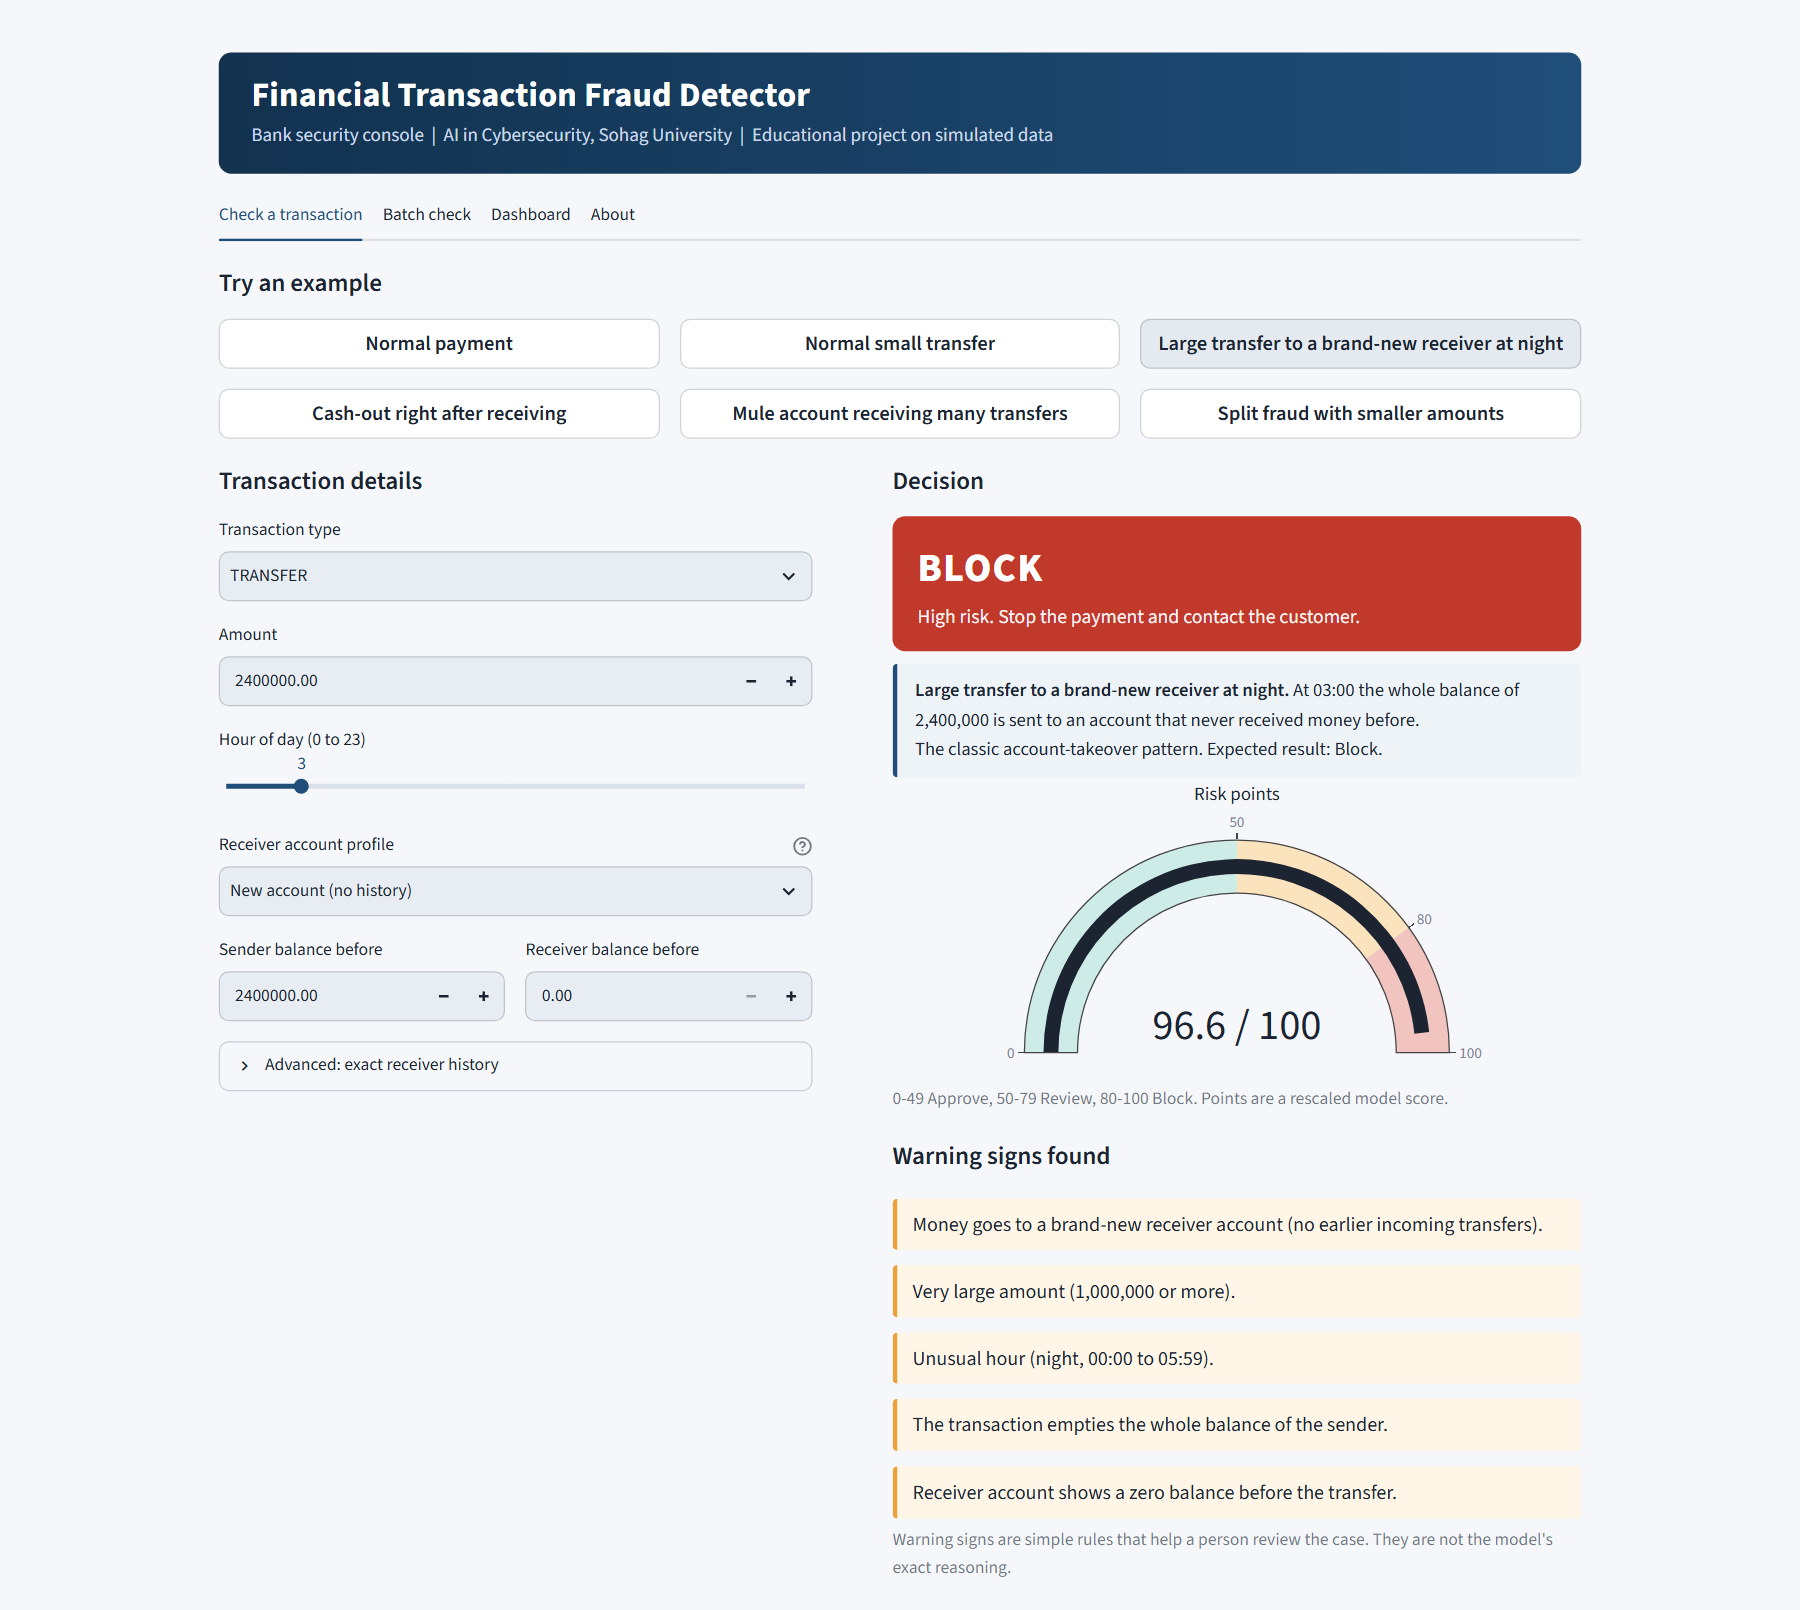

04_batch.png


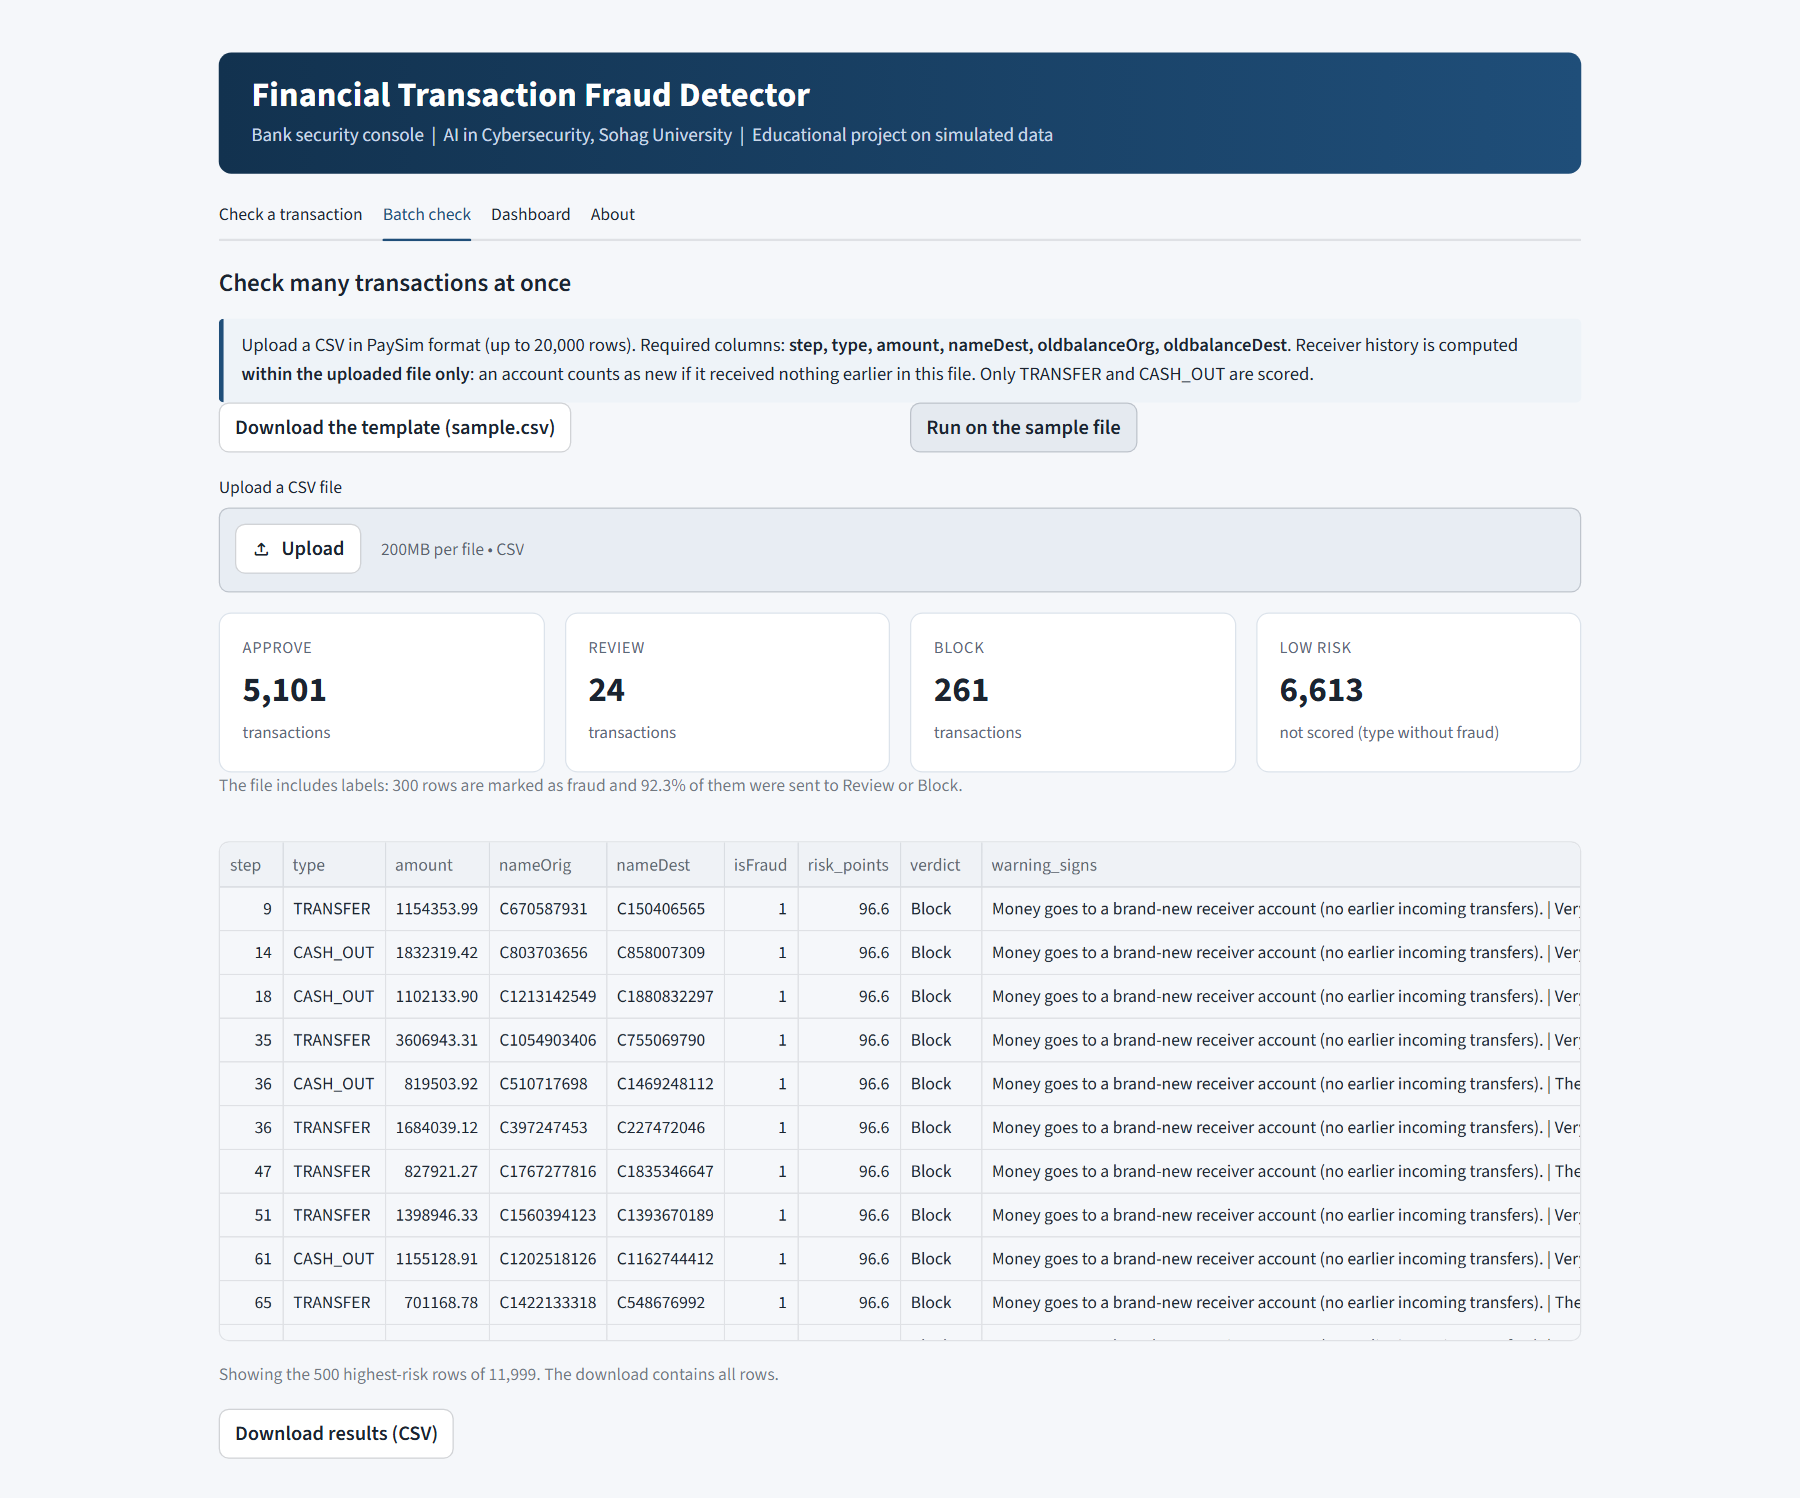

05_dashboard.png


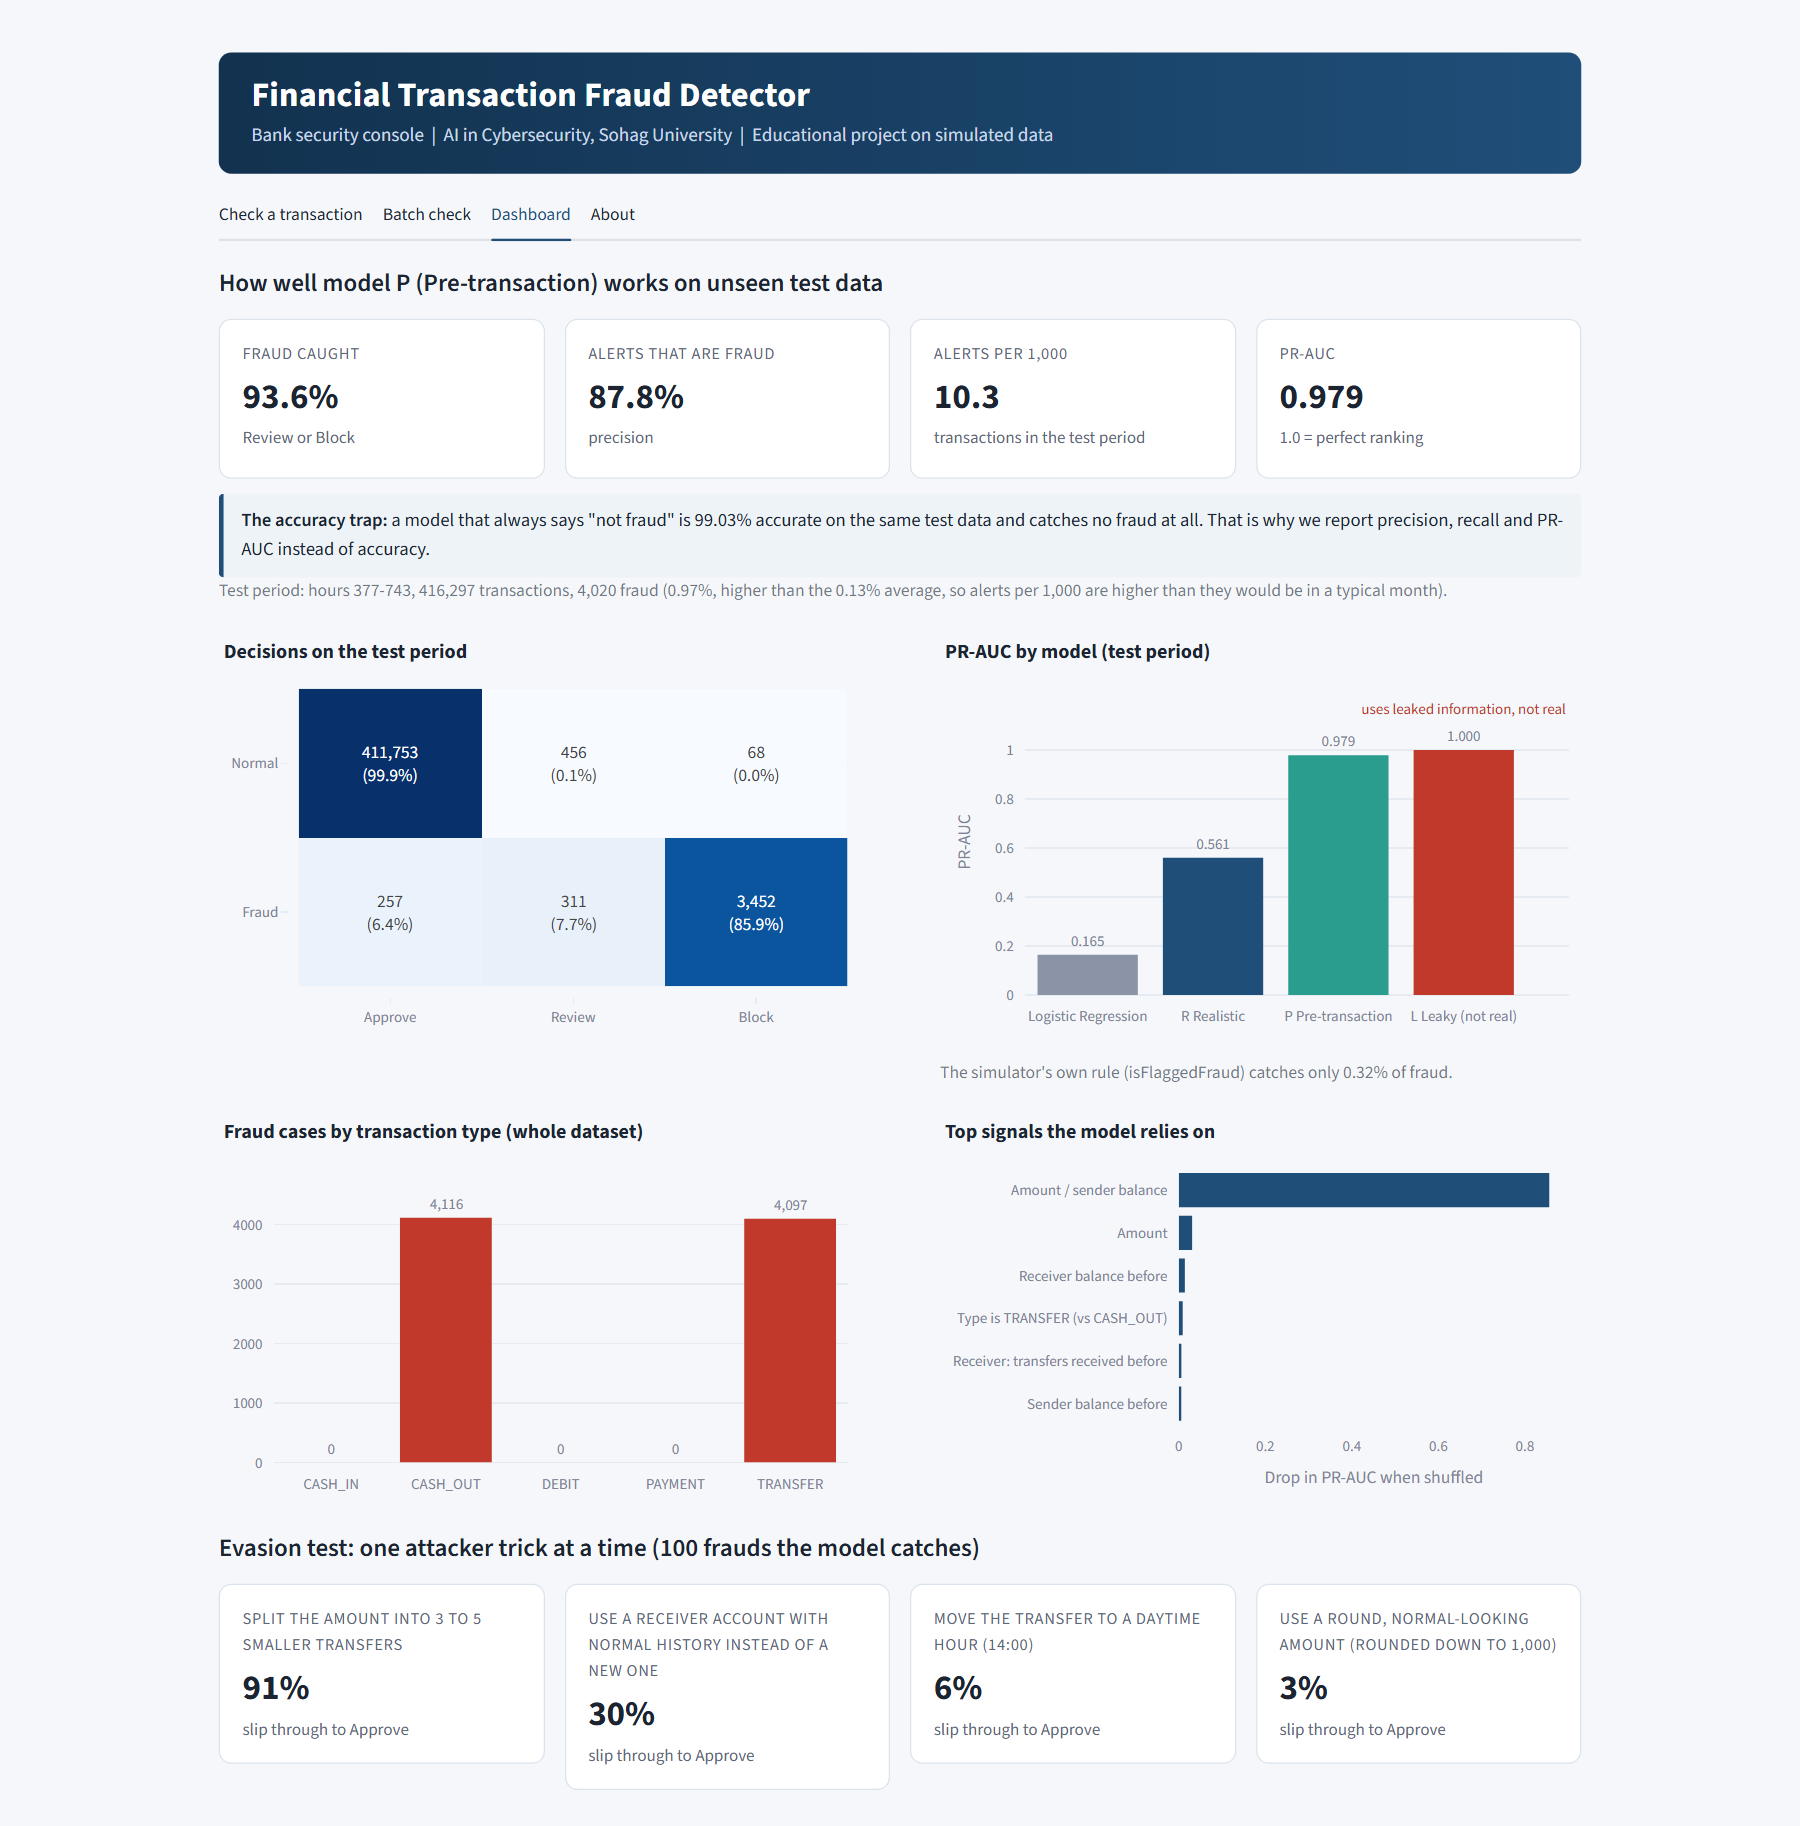

In [10]:
screens = data.REPORTS / "screens"
for name in ["01_check_block.png", "04_batch.png", "05_dashboard.png"]:
    path = screens / name
    if path.exists():
        print(name)
        display(Image(filename=str(path), width=900))
    else:
        print(f"{name} not found yet: run tools/screenshot_app.py")

In [11]:
data.write_json({"presets": rows, "sample_batch": {"rows": int(len(df_in)), "counts": {k: int(v) for k, v in counts.items()},
                 "labeled_fraud_flagged_pct": float(100 * caught), "normal_flagged": int(false_alarms)}},
                data.REPORTS / "app_presets.json")
verdict_of = {r["key"]: r["verdict"] for r in rows}
data.write_findings("05_deployment", [
    "The app is one Streamlit file (app.py) that reuses src/, reads only repository files and makes no network calls.",
    f"Presets: normal payment {verdict_of['normal_payment']}, normal small transfer {verdict_of['small_transfer']}, night transfer to a new receiver {verdict_of['night_new_receiver']}, cash-out after receiving {verdict_of['cash_out_after_receiving']}.",
    f"Two presets show known limitations honestly: the busy mule account ({verdict_of['mule_many_transfers']}) and the split fraud ({verdict_of['split_fraud']}).",
    f"Batch check on data/sample.csv ({len(df_in):,} rows): {100 * caught:.1f}% of the labeled fraud rows go to Review or Block, with {false_alarms} normal rows flagged.",
    f"{summary.split(' in ')[0]}; deployment uses requirements.txt (runtime only, exact versions) on Python 3.11.",
])
print("Saved reports/app_presets.json and findings.")

Saved reports/app_presets.json and findings.


## Key findings

- The app is one Streamlit file (app.py) that reuses src/, reads only repository files and makes no network calls.
- Presets: normal payment Low risk, normal small transfer Approve, night transfer to a new receiver Block, cash-out after receiving Block.
- Two presets show known limitations honestly: the busy mule account (Approve) and the split fraud (Approve).
- Batch check on data/sample.csv (11,999 rows): 92.3% of the labeled fraud rows go to Review or Block, with 8 normal rows flagged.
- 28 passed; deployment uses requirements.txt (runtime only, exact versions) on Python 3.11.